## Historical VaR and Expected Shortfall

- **Portfolio:** USD 5,000 — 50% AVGO, 25% QQQ, 15% MRVL and 10% TSLA
- **Time horizon:** 5 trading days
- **Lookback period:** 5 years
- **Confidence levels:** 90%, 95% and 99%

Five years of cleaned daily log returns are used to construct rolling five-day portfolio returns. Historical VaR is estimated from the 10th, 5th and 1st percentiles of the empirical return distribution. Expected Shortfall is calculated as the average loss beyond each corresponding VaR threshold.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import norm

In [2]:
tickers = ["QQQ", "MRVL", "TSLA", "AVGO"]
weights = np.array([0.25, 0.15, 0.1, 0.5])
portfolio_value = 5000
time_horizon = 5 #in days

In [3]:
log_returns = pd.read_csv("cleaned_log_returns.csv", index_col="Date", parse_dates=True)
log_returns = log_returns.reindex(columns=tickers)
display(log_returns.head())

,QQQ,MRVL,TSLA,AVGO
Date,,,,
2021-11-15,-0.000228,-0.007650,-0.019573,0.004517
2021-11-16,0.007096,0.012267,0.039984,0.005288
2021-11-17,0.000528,-0.002441,0.031984,0.001529
2021-11-18,0.010308,0.020298,0.006745,0.009035
2021-11-19,0.005560,-0.007614,0.036432,-0.010651


In [4]:
portfolio_returns = log_returns.dot(weights)
portfolio_returns_5d =portfolio_returns.rolling(window=time_horizon).sum().dropna()

In [5]:
confidence_levels = [0.90, 0.95, 0.99]
VaR_values = []
ES_values = []

for confidence_level in confidence_levels:
    tail_percentile = (1 - confidence_level) * 100
    return_threshold = np.percentile(portfolio_returns_5d,tail_percentile)
    tail_returns = portfolio_returns_5d[portfolio_returns_5d <= return_threshold]
    var = (-return_threshold * portfolio_value)
    es = (-np.mean(tail_returns) * portfolio_value)
    VaR_values.append(var)
    ES_values.append(es)
    print(f"{confidence_level:.0%} Historical VaR: ${var:,.2f}")
    print(f"{confidence_level:.0%} Historical ES: ${es:,.2f}")

90% Historical VaR: $277.43
90% Historical ES: $428.49
95% Historical VaR: $393.27
95% Historical ES: $530.46
99% Historical VaR: $616.72
99% Historical ES: $707.62


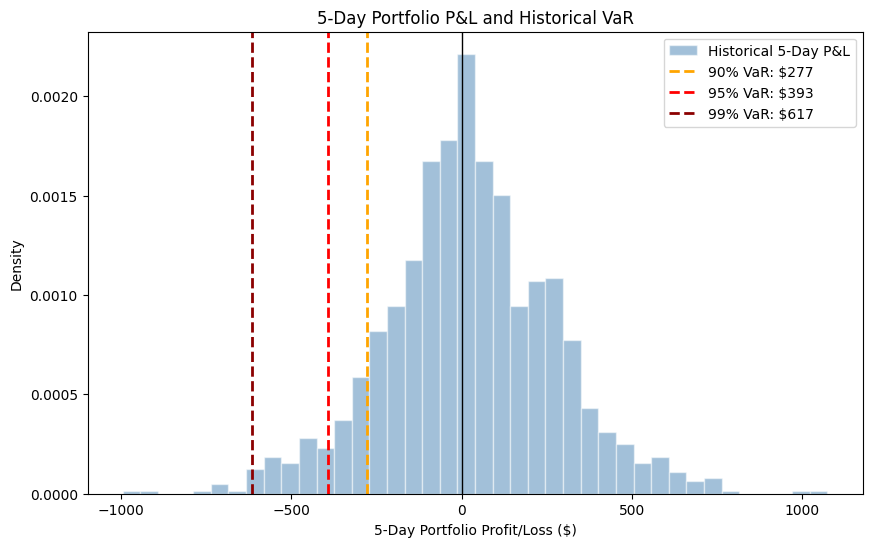

In [6]:
pnl_5d = portfolio_returns_5d * portfolio_value
plt.figure(figsize=(10, 6))
plt.hist(
    pnl_5d,
    bins=40,
    density=True,
    alpha=0.5,
    color="steelblue",
    edgecolor="white",
    label="Historical 5-Day P&L"
)

colors = ["orange", "red", "darkred"]
for confidence_level, var, color in zip(
    confidence_levels,
    VaR_values,
    colors
):
    plt.axvline(
        x=-var,
        color=color,
        linestyle="--",
        linewidth=2,
        label=f"{confidence_level:.0%} VaR: ${var:,.0f}"
    )
plt.axvline(x=0, color="black", linewidth=1)

plt.xlabel("5-Day Portfolio Profit/Loss ($)")
plt.ylabel("Density")
plt.title("5-Day Portfolio P&L and Historical VaR")
plt.legend()
plt.show()

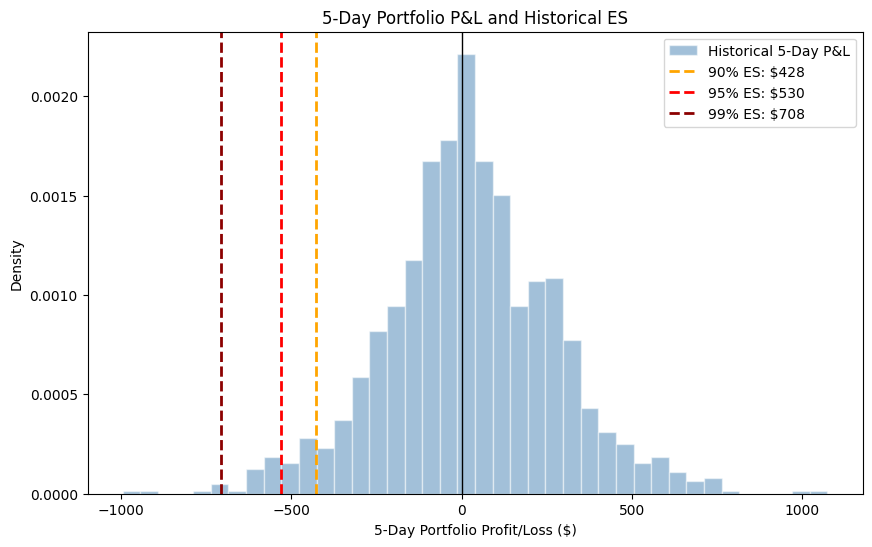

In [7]:
pnl_5d = portfolio_returns_5d * portfolio_value
plt.figure(figsize=(10, 6))
plt.hist(
    pnl_5d,
    bins=40,
    density=True,
    alpha=0.5,
    color="steelblue",
    edgecolor="white",
    label="Historical 5-Day P&L"
)

colors = ["orange", "red", "darkred"]
for confidence_level, es, color in zip(
    confidence_levels,
    ES_values,
    colors
):
    plt.axvline(
        x=-es,
        color=color,
        linestyle="--",
        linewidth=2,
        label=f"{confidence_level:.0%} ES: ${es:,.0f}"
    )
plt.axvline(x=0, color="black", linewidth=1)

plt.xlabel("5-Day Portfolio Profit/Loss ($)")
plt.ylabel("Density")
plt.title("5-Day Portfolio P&L and Historical ES")
plt.legend()
plt.show()